In [3]:
# Purpose: Load the cleaned and scaled Sahiwal soil dataset for exploratory analysis.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data_path = "../data/processed/sahiwal_soil_dataset_scaled.csv"

soil_data = pd.read_csv(data_path)

print("Dataset shape:", soil_data.shape)
display(soil_data.head())

Dataset shape: (48807, 9)


,longitude,latitude,ph,soc_g_kg,nitrogen_g_kg,clay_pct,sand_pct,silt_pct,cec_cmol_kg
0,73.166888,30.8821,7.9,7.9,0.92,25.2,43.9,30.9,15.6
1,73.169507,30.8821,7.8,8.0,0.92,24.4,43.2,32.4,15.3
2,73.172127,30.8821,7.8,8.4,1.02,23.8,43.3,32.9,15.3
3,73.174746,30.8821,7.9,9.5,1.11,24.2,41.2,34.6,15.4
4,73.177366,30.8821,7.9,9.4,1.10,24.2,40.9,34.9,14.8


In [4]:
# Purpose: Examine the statistical distribution and range of each soil property.

soil_data.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,48807.0,72.880026,0.246369,72.406025,72.667573,72.888117,73.089553,73.342109
latitude,48807.0,30.555256,0.145626,30.201183,30.450628,30.558496,30.664117,30.882100
ph,48807.0,7.798728,0.097648,7.400000,7.800000,7.800000,7.900000,8.200000
soc_g_kg,48807.0,10.450982,0.875534,6.400000,9.900000,10.400000,11.000000,23.600000
nitrogen_g_kg,48807.0,1.244739,0.271135,0.780000,1.080000,1.150000,1.280000,2.350000
clay_pct,48807.0,22.521991,1.428533,18.300000,21.500000,22.400000,23.400000,31.100000
sand_pct,48807.0,42.953136,2.014040,36.200000,41.600000,42.800000,44.100000,50.900000
silt_pct,48807.0,34.524808,2.263184,25.100000,33.000000,34.600000,36.100000,41.700000
cec_cmol_kg,48807.0,15.264351,1.161636,11.400000,14.300000,15.200000,16.100000,19.400000


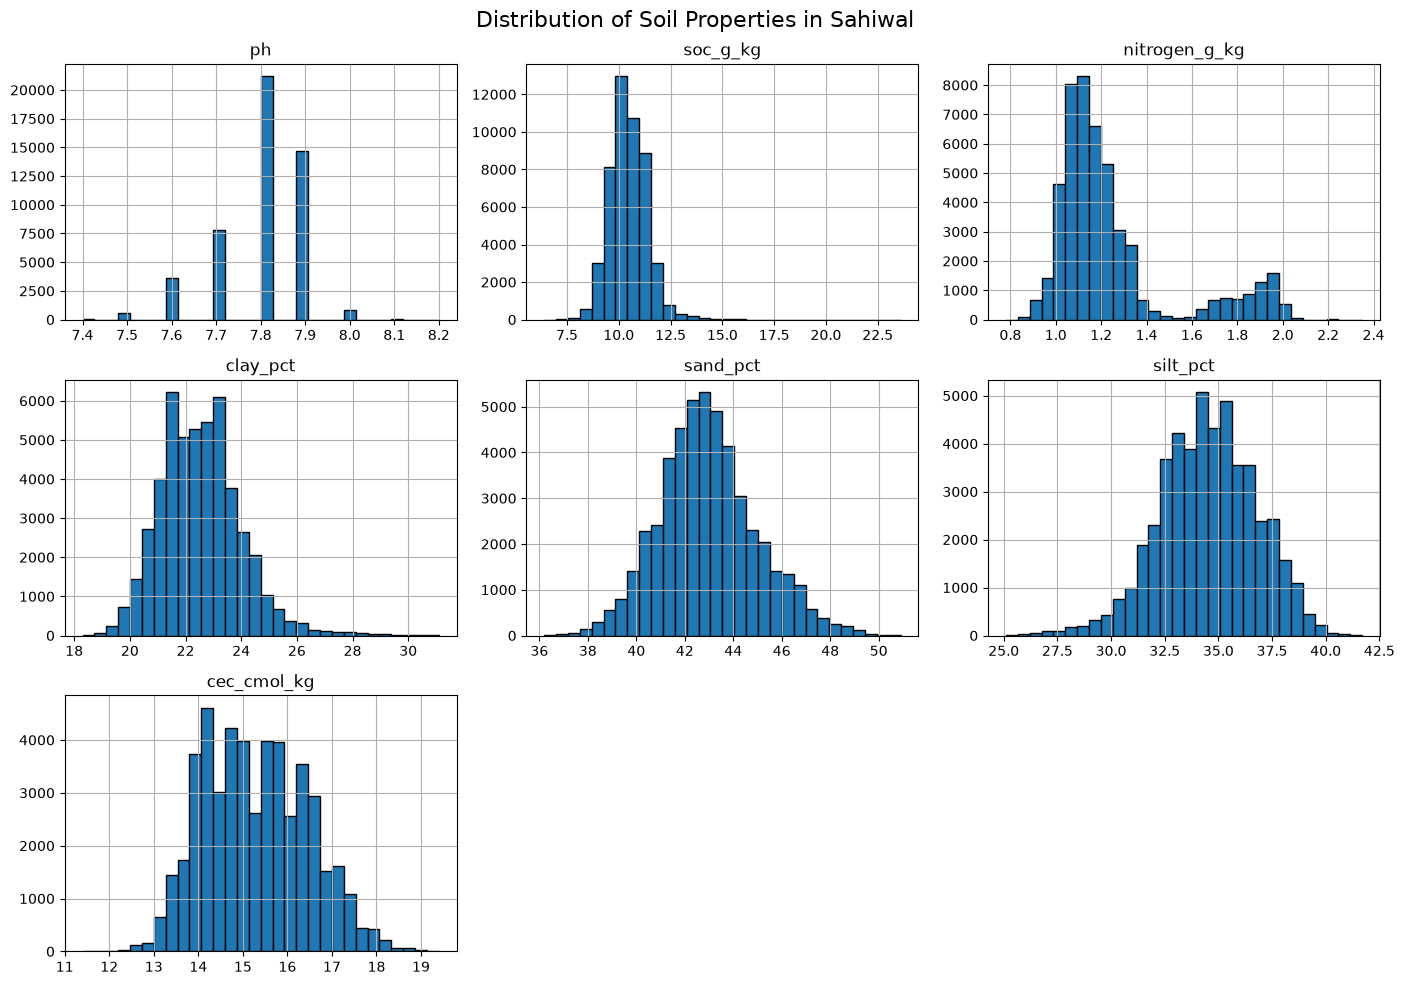

In [5]:
# Purpose: Visualize the distribution of all seven soil properties using histograms.

soil_features = [
    'ph', 'soc_g_kg', 'nitrogen_g_kg',
    'clay_pct', 'sand_pct', 'silt_pct', 'cec_cmol_kg'
]

soil_data[soil_features].hist(
    bins=30,
    figsize=(14, 10),
    edgecolor='black'
)

plt.suptitle("Distribution of Soil Properties in Sahiwal", fontsize=16)
plt.tight_layout()
plt.show()

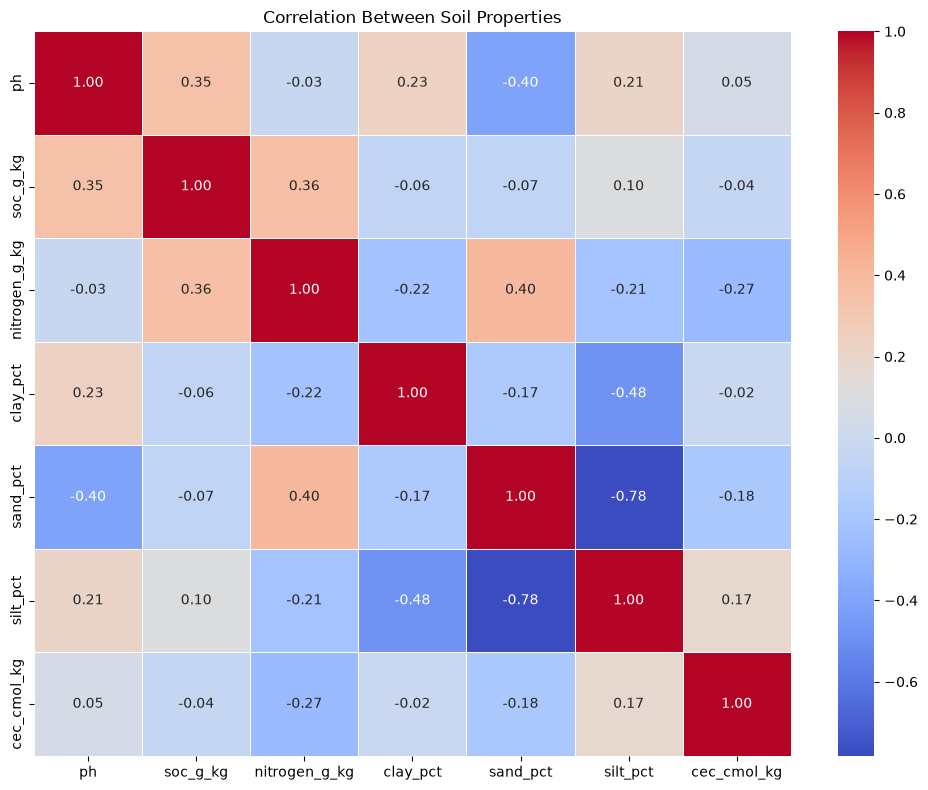

In [6]:
# Purpose: Calculate and visualize relationships between soil properties.

correlation_matrix = soil_data[soil_features].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Between Soil Properties")
plt.tight_layout()
plt.show()

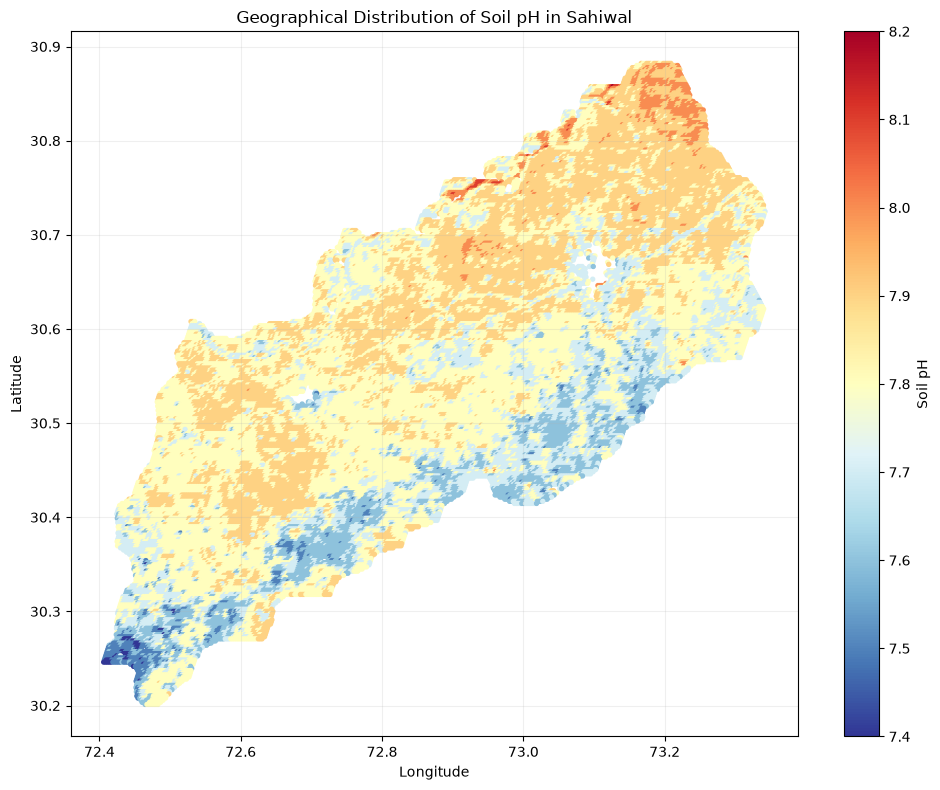

In [7]:
# Purpose: Visualize geographical variation in soil pH across Sahiwal.

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    soil_data['longitude'],
    soil_data['latitude'],
    c=soil_data['ph'],
    cmap='RdYlBu_r',
    s=8
)

plt.colorbar(scatter, label='Soil pH')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Geographical Distribution of Soil pH in Sahiwal')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

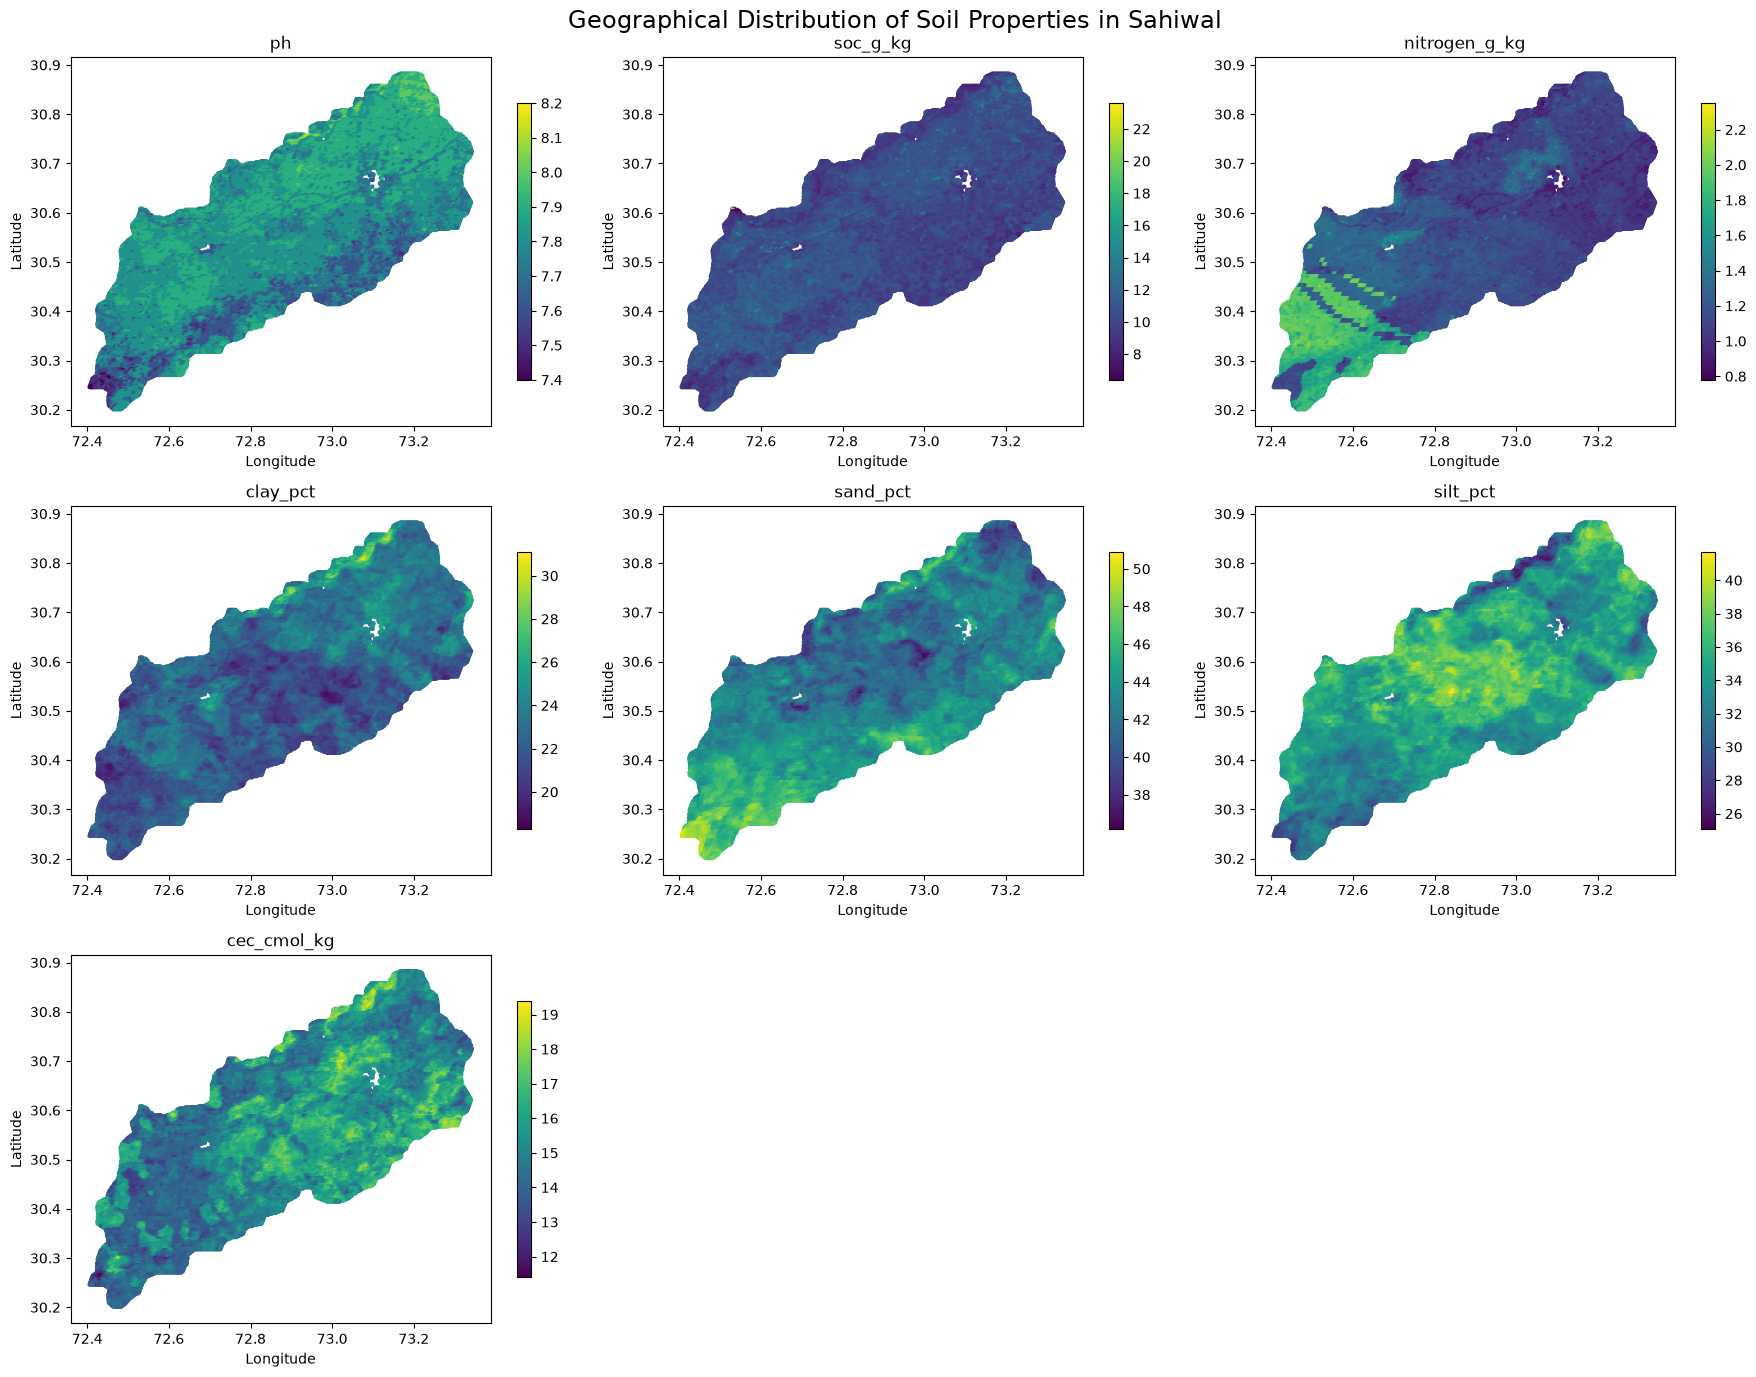

In [8]:
# Purpose: Compare the geographical distribution of all seven soil properties.

fig, axes = plt.subplots(3, 3, figsize=(18, 14))

for ax, feature in zip(axes.flat, soil_features):
    scatter = ax.scatter(
        soil_data['longitude'],
        soil_data['latitude'],
        c=soil_data[feature],
        cmap='viridis',
        s=5
    )

    ax.set_title(feature)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    fig.colorbar(scatter, ax=ax, shrink=0.75)

for ax in axes.flat[len(soil_features):]:
    ax.set_visible(False)

plt.suptitle('Geographical Distribution of Soil Properties in Sahiwal', fontsize=17)
plt.tight_layout()
plt.show()

1. SOC and nitrogen

Both show similar high-value areas in the northeast. This agrees with their positive correlation of 0.36.

2. Clay and sand

Their geographical patterns appear partly opposite. This is consistent with the negative relationship between soil texture components.

3. CEC and clay

CEC increases toward the north, but its overall correlation with clay is nearly zero (-0.02). This is a useful reminder: geographical patterns can be more complicated than simple overall correlations.

In [9]:
# Purpose: Check whether sand, silt, and clay percentages approximately sum to 100%.

soil_data['texture_total'] = (
    soil_data['sand_pct'] +
    soil_data['silt_pct'] +
    soil_data['clay_pct']
)

print("Texture percentage statistics:")
display(soil_data['texture_total'].describe())

print("Average texture total:", soil_data['texture_total'].mean())

Texture percentage statistics:


count    48807.000000
mean        99.999934
std          0.049812
min         99.900000
25%        100.000000
50%        100.000000
75%        100.000000
max        100.100000
Name: texture_total, dtype: float64

Average texture total: 99.99993443563423


# Exploratory Data Analysis (EDA) — SoilSenseAI

## 1. Dataset Overview

The Sahiwal soil dataset was loaded and analyzed to understand the distribution, relationships, and geographical variation of soil properties.

- **Total observations:** 48,807
- **Total columns:** 9
- **Geographical features:** Longitude and Latitude
- **Soil properties:** pH, Soil Organic Carbon (SOC), Nitrogen, Clay, Sand, Silt, and Cation Exchange Capacity (CEC).
- **Missing values:** None identified in the cleaned dataset.

## 2. Descriptive Statistical Analysis

Descriptive statistics were calculated to examine the mean, standard deviation, minimum, maximum, and quartiles of each soil property.

Key observations:

- **pH:** Mean of 7.80, indicating generally alkaline soil.
- **SOC:** Mean of 10.45 g/kg.
- **Nitrogen:** Mean of 1.24 g/kg.
- **Clay:** Mean of 22.52%.
- **Sand:** Mean of 42.95%.
- **Silt:** Mean of 34.52%.
- **CEC:** Mean of 15.26 cmol/kg.

## 3. Distribution Analysis

Histograms were generated to examine the distribution of individual soil properties.

Major observations:

- Soil pH values are concentrated around 7.8–7.9.
- SOC values are mainly concentrated around 10–11 g/kg.
- Nitrogen shows a potentially bimodal or uneven distribution.
- Clay, sand, and silt exhibit relatively concentrated distributions.
- CEC values are mainly concentrated around 14–16 cmol/kg.

## 4. Correlation Analysis

A Pearson correlation matrix was generated to investigate relationships between soil properties.

Important findings:

| Relationship | Correlation |
|---|---:|
| Sand and Silt | -0.78 |
| Clay and Silt | -0.48 |
| pH and Sand | -0.40 |
| SOC and Nitrogen | +0.36 |
| pH and SOC | +0.35 |
| Nitrogen and CEC | -0.27 |

The strongest negative correlation was observed between sand and silt (-0.78). SOC and nitrogen showed a positive correlation (+0.36).

These relationships may help guide feature selection during model development. Correlation does not establish causation.

## 5. Geographical Analysis

Geographical scatter maps were generated to investigate the spatial distribution of all seven soil properties across Sahiwal.

Key observations:

- **pH:** Relatively higher values in northern and northwestern areas, with lower values in southern and southwestern areas.
- **SOC and Nitrogen:** Higher-value pockets were observed in parts of the northeastern region.
- **Clay:** Generally higher toward northern and northeastern areas.
- **Sand:** Generally higher in western and southwestern areas.
- **Silt:** Higher concentrations were observed in central and northern areas.
- **CEC:** Generally higher toward northern and northeastern areas.

These patterns suggest that geographical coordinates may provide useful information for spatial prediction.

## 6. Soil Texture Validation

The relationship between sand, silt, and clay was examined.

Their percentages approximately sum to 100%:

- **Mean:** 99.999934%
- **Minimum:** 99.9%
- **Maximum:** 100.1%
- **Standard deviation:** 0.049812

The small differences are consistent with rounding.

## 7. Conclusion

The exploratory analysis revealed meaningful statistical and geographical patterns in Sahiwal's soil properties.

The findings suggest that:

1. Soil properties exhibit spatial variation across the district.
2. Some soil properties have measurable relationships with one another.
3. Geographic coordinates may be useful predictive features.
4. Soil texture components are mathematically dependent because their percentages approximately sum to 100%.

**Next Phase:** Feature Engineering and Machine Learning Preparation.

The next stage will focus on preparing meaningful input features and defining suitable prediction tasks for SoilSenseAI.

---

*Data source: ISRIC SoilGrids. The observations represent gridded soil-property estimates rather than individual laboratory soil samples.*